# Homework 10: Midterm 2 practice exam

This practice exam has four sections *in the same order as the exam.*
Each section has short warm-ups followed by questions about one code cell.
Predict each warm-up result before checking it in the [Homework 10 hints notebook](https://colab.research.google.com/github/wfreinhart/matse219/blob/main/notebooks/Homework10Hints.ipynb).
> Reading the cell's output isn't practice! You must predict it in advance.

Note that the exam itself won't include the warm-ups.
The exam-style questions have the same parts and point values as the exam.

This homework will be graded for completion:
you earn credit for a genuine attempt at every part, even if your answer is wrong.

You may also run the cells at the bottom to check and revise your answers.

## Submission instructions

Upload the `ipynb` file to Canvas:
> File -> Download -> ipynb -> upload to Canvas (like any other file)

The `ipynb` file type is the only accepted format.
Save a copy before beginning.
Reloading or disconnecting can revert the notebook to the instructor copy.

# Problem 0 (-10 pts if blank): generative AI usage statement

As you work on this assignment, feel free to use generative AI tools to help you learn,
understand, and debug Python code. In particular, you could get hints or conceptual guidance in
the implementation you write yourself.

However, you must clearly disclose and cite all use of AI. You must include:
1. The name(s) of the AI tool(s) used.
2. The specific prompt(s) you used to generate the content.
3. A description of how you used the output and what edits or additions you made to integrate it
   into your own work.

You are fully responsible for the final submitted work. Critically evaluate, fact-check, and
verify all AI-generated content for validity. Failure to properly cite and disclose AI use
constitutes plagiarism under Penn State's Academic Integrity policy.

Write your disclosure (or "I did not use an AI tool for this assignment") in the cell below.

*your disclosure here*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy import optimize

# 1. Functions, loops, and conditionals (25 points)

A case-hardened steel gear has a hard surface and a softer core.
Hardness is measured in Vickers units (HV), and a higher number is harder.
The readings below were taken at five depths below the tooth surface, from the core side toward the surface.
A reading must be at least 550 HV to meet the specification.
The code labels any reading under 450 HV as core.

## Warm-up (no points)

The exam has no warm-ups, so these are not scored.

**1a.** What does this print?
```python
def double(x):
    print(2 * x)

y = double(4)
print(y)
```

*your answer here*

**1b.** What does this print?
```python
def scale(value, factor=10):
    return value * factor

print(scale(3), scale(3, factor=2))
```

*your answer here*

**1c.** What does this print?
```python
def combine(a, b):
    return a - b, a + b

d, s = combine(9, 4)
print(d, s)
```

*your answer here*

**1d.** Fill in the keyword that ends the loop at the first value above 3.
```python
for v in [1, 2, 5, 3]:
    if v > 3:
        ________
    print(v)
```

*your answer here*

## Exam-style cell (25 points)

Read the code and its printed results before answering.

In [2]:
def check_hardness(hv, limit_hv=550):
    """Margin over the required hardness, and whether the reading passes.
    hv:        Vickers hardness reading in HV
    limit_hv:  required minimum hardness in HV
    """
    margin_hv = hv - limit_hv
    return margin_hv, margin_hv >= 0

depths_mm = [1.2, 0.9, 0.6, 0.3, 0.1]
hardness_hv = [380, 430, 540, 585, 720]

for i in range(len(depths_mm)):
    margin_hv, passes = check_hardness(hardness_hv[i])
    if hardness_hv[i] < 450:
        print(depths_mm[i], 'mm: core')
    elif passes:
        print(depths_mm[i], 'mm: above the limit by', margin_hv, 'HV')
        break
    else:
        print(depths_mm[i], 'mm: below the limit by', -margin_hv, 'HV')
# prints 1.2 mm: core
#        0.9 mm: core
#        0.6 mm: below the limit by 10 HV
#        0.3 mm: above the limit by 35 HV

1.2 mm: core
0.9 mm: core
0.6 mm: below the limit by 10 HV
0.3 mm: above the limit by 35 HV


**1e (10 points).** The output has no line for the 0.1 mm reading. Why not?

*your answer here*

**1f (11 points).** `check_hardness` ends with `return` and prints nothing. What would happen at line 13 if the function printed the margin and the result instead of returning them, and why?

*your answer here*

**1g (4 points).** Complete the line so it checks the 0.1 mm reading against a 600 HV requirement from a customer, by naming the input.
```python
margin_hv, passes = check_hardness(hardness_hv[4], ____)
print(margin_hv)
```

*your answer here*

# 2. Fitting with curve_fit (25 points)

A polymer film sits between two electrodes, and a voltage step is applied.
The current through it falls with time as the polymer's dipoles line up with the field.
`t_s` (time in s) and `current_nA` (current in nA) hold 12 readings.
A simple model has the form current = a e^(-bt), where `a` is the current at t = 0 and 1/b is the time for the current to fall to 1/e (about 37%) of any earlier value.
The readings are synthetic, generated for this practice exam.

## Warm-up (no points)

The exam has no warm-ups, so these are not scored.

**2a.** `optimize.curve_fit(model, x, y)` returned `popt` printing as `[3. 2.]`, for `def model(x, a, b):`. Which number is `b`?
```python
def model(x, a, b):
    return a * x**b

popt, pcov = optimize.curve_fit(model, x, y)
print(popt)   # prints [3. 2.]
```

*your answer here*

**2b.** Fill in the keyword that sets the starting values.
```python
popt, pcov = optimize.curve_fit(model, x, y, ____=[3, 2])
```

*your answer here*

**2c.** What does this print?
```python
def model(x, a, b):
    return a * x**b

print(model(2, *[1, 3]))
```

*your answer here*

## Exam-style cell (25 points)

Read the code and its printed results before answering.

Run this cell first.
It defines the data for the cell below.

In [3]:
t_s = np.array([2, 4, 6, 8, 12, 16, 24, 32, 40, 52, 64, 80])
current_nA = np.array([62.9, 54.6, 49.1, 44.0, 36.5, 32.8, 26.4, 22.2, 17.9, 14.3, 10.9, 8.2])

In [4]:
def decay_model(t, a, b):
    """Current in nA from a * exp(-b * t).
    t:  time in s (a number or an array)
    a:  current at t = 0 in nA
    b:  decay rate in 1/s
    """
    return a * np.exp(-b * t)

popt, pcov = optimize.curve_fit(decay_model, t_s, current_nA, p0=[60, 0.1])
print(f'a = {popt[0]:.1f} nA, b = {popt[1]:.4f} 1/s')   # prints a = 60.4 nA, b = 0.0320 1/s
print(f'{1 / popt[1]:.0f} s')                            # prints 31 s

popt_bad, pcov_bad = optimize.curve_fit(decay_model, t_s, current_nA, p0=[60, 500])
print(f'a = {popt_bad[0]:.1f}, b = {popt_bad[1]:.1f}')   # prints a = 60.0, b = 500.0
print(np.max(decay_model(t_s, *popt_bad)))   # prints 0.0
print(np.max(current_nA))                    # prints 62.9

a = 60.4 nA, b = 0.0320 1/s
31 s
a = 60.0, b = 500.0
0.0
62.9


/var/folders/gp/17x29r6s3l7dzdvpf785tzw40000gn/T/ipykernel_34180/1144254363.py:13: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_bad, pcov_bad = optimize.curve_fit(decay_model, t_s, current_nA, p0=[60, 500])


Run this cell to draw the figure.
On the exam the figure is printed with a caption.

Text(0, 0.5, 'residual (nA)')

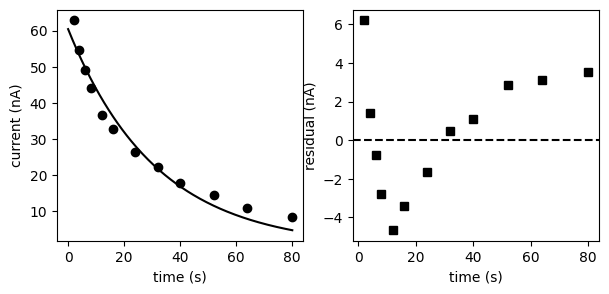

In [5]:
t_line = np.linspace(0, 80, 200)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].plot(t_s, current_nA, 'o', color='black')
axes[0].plot(t_line, decay_model(t_line, *popt), '-', color='black')
axes[0].set_xlabel('time (s)')
axes[0].set_ylabel('current (nA)')
axes[1].plot(t_s, current_nA - decay_model(t_s, *popt), 's', color='black')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel('residual (nA)')

The left panel shows the readings (circles) and the curve from the first fit (line).
The right panel shows the residuals of the first fit.

**2d (8 points).** Line 11 prints 31 s, which is 1/b for this film. A second film, tested the same way, has 1/b = 8 s. According to the fitted model, which of the two films holds its current longer, and why?

*your answer here*

**2e (8 points).** The second fit started from `p0=[60, 500]` and failed. Give two pieces of evidence printed in the code that support this.

*your answer here*

**2f (9 points).** The residuals in the right panel are positive at first, negative in the middle, and positive late. Explain why a pattern like this, rather than random scatter around zero, is evidence that the model is missing something. State what random scatter would indicate and what conclusion this pattern supports.

*your answer here*

# 3. Fitting with minimize (25 points)

An aluminum alloy is aged at a fixed temperature, and tiny particles form inside it and harden it.
`aging_h` is the aging time in hours, and `gain_GPa` is the increase in yield strength over the as-quenched alloy, in GPa.
The code fits the model gain = A (1 - e^(-kt)) by minimizing the sum of squared residuals.
`A` (in GPa) is the model's largest possible gain, and `k` (in 1/h) is the rate at which the gain approaches it.
A straight line fitted to the same readings has an RMSE of 0.0166 GPa.
The readings are synthetic, generated for this practice exam.

## Warm-up (no points)

The exam has no warm-ups, so these are not scored.

**3a.** What does this print?
```python
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(f'{res.x[0]:.2f}')
```

*your answer here*

**3b.** What happens when this runs?
```python
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(res.success())
```

*your answer here*

**3c.** Fill in the NumPy function that makes the objective a sum of squared residuals.
```python
def objective(params):
    residuals = y - model(x, *params)
    return np.________(residuals**2)
```

*your answer here*

## Exam-style cell (25 points)

Read the code and its printed results before answering.

Run this cell first.
It defines the data for the cell below.

In [6]:
aging_h = np.array([1, 2, 4, 8, 16, 32])
gain_GPa = np.array([0.015, 0.028, 0.050, 0.087, 0.113, 0.144])

In [7]:
def sum_sq(params):
    A, k = params
    gain_model = A * (1 - np.exp(-k * aging_h))
    residuals = gain_GPa - gain_model
    return np.sum(residuals**2)

res = optimize.minimize(sum_sq, [0.1, 0.1])
A_fit, k_fit = res.x
print(f'A = {A_fit:.3f} GPa, k = {k_fit:.3f} 1/h')   # prints A = 0.147 GPa, k = 0.104 1/h
print(f'{res.fun:.1e}')                              # prints 5.9e-05
print(res.success)                                   # prints True

print(f'saturating model RMSE = {np.sqrt(res.fun / len(aging_h)):.4f} GPa')   # prints saturating model RMSE = 0.0031 GPa

A = 0.147 GPa, k = 0.104 1/h
5.9e-05
True
saturating model RMSE = 0.0031 GPa


The reading at 8 h was typed as 0.87 GPa instead of 0.087. Refitting the model with the same least-squares objective, and with a mean-absolute-error objective as in class (using `method='Nelder-Mead'`, a solver option from class), prints:

```text
least squares: A = 0.305 GPa, k = 0.314 1/h
minimum MAE:   A = 0.149 GPa, k = 0.104 1/h
```

**3d (7 points).** Line 10 prints `5.9e-05`. What does this number add up, and what are its units?

*your answer here*

**3e (8 points).** Line 13 prints the model's RMSE, 0.0031 GPa. What does this number say about its misses, and, comparing it with the straight line's 0.0166 GPa, which form has the closer fit to the readings?

*your answer here*

**3f (10 points).** Look at the two refits printed after the code. Explain why the least-squares values move far from the fit on the good readings while the minimum-MAE values stay close, and say what you should do about the reading at 8 h.

*your answer here*

# 4. Fitting a plane and reading a contour (25 points)

A cold-worked metal sheet was annealed, which means heated so that its grains can grow.
`T_C` (anneal temperature in C), `t_h` (hold time in h) and `grain_um` (average grain diameter in micrometers) hold 15 samples.
The code fits the plane grain = a + b T + c t by minimizing the mean squared residual.
`rmse` is the function from class.
The data are synthetic, generated for this practice exam.

## Warm-up (no points)

The exam has no warm-ups, so these are not scored.

**4a.** What does this print?
```python
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(0, 1, 3, 4, 5))
```

*your answer here*

**4b.** Fill in the keyword that shades each point by the values in `z`.
```python
fig, ax = plt.subplots()
ax.scatter(x, y, ____=z, cmap='Greys')
```

*your answer here*

**4c.** What does this print?
```python
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(1, 0, *[3, 4, 5]))
```

*your answer here*

## Exam-style cell (25 points)

Read the code and its printed results before answering.

Run this cell first.
It defines the data for the cell below.

In [8]:
T_C = np.array([600, 625, 650, 675, 700, 600, 625, 650, 675, 700, 600, 625, 650, 675, 700])
t_h = np.array([1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 9, 9, 9, 9, 9])
grain_um = np.array([6.6, 7.1, 8.6, 11.3, 15.2, 8.0, 9.6, 13.2, 17.4, 24.3, 11.1, 13.7, 19.6, 26.7, 38.4])

def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

In [9]:
def plane(T, t, a, b, c):
    return a + b * T + c * t

def mse_plane(params):
    a, b, c = params
    residuals = grain_um - plane(T_C, t_h, a, b, c)
    return np.mean(residuals**2)

res = optimize.minimize(mse_plane, [0, 0.1, 1])
a_fit, b_fit, c_fit = res.x
print(f'b = {b_fit:.3f} um per C, c = {c_fit:.2f} um per h')   # prints b = 0.173 um per C, c = 1.45 um per h
print(res.success)                                             # prints True

grain_fit = plane(T_C, t_h, *res.x)
print(f'RMSE of the plane = {rmse(grain_um, grain_fit):.1f} um')   # prints RMSE of the plane = 3.2 um
print(f'RMSE of the mean = {np.std(grain_um):.1f} um')             # prints RMSE of the mean = 8.5 um

T_span = np.max(T_C) - np.min(T_C)
t_span = np.max(t_h) - np.min(t_h)
print(f'temperature, over {T_span:.0f} C: {b_fit * T_span:.0f} um of grain diameter')   # prints temperature, over 100 C: 17 um of grain diameter
print(f'hold time, over {t_span:.0f} h: {c_fit * t_span:.0f} um of grain diameter')       # prints hold time, over 8 h: 12 um of grain diameter
print(f'{plane(550, 0.5, *res.x):.0f} um')                                               # prints -7 um

b = 0.173 um per C, c = 1.45 um per h
True
RMSE of the plane = 3.2 um
RMSE of the mean = 8.5 um
temperature, over 100 C: 17 um of grain diameter
hold time, over 8 h: 12 um of grain diameter
-7 um


Run this cell to draw the figure.
On the exam the figure is printed with a caption.

Text(0, 0.5, 'hold time (h)')

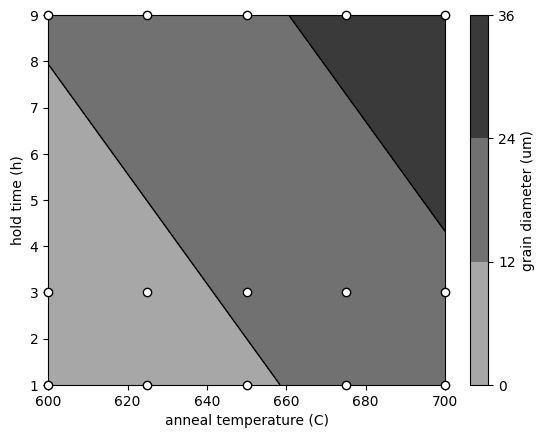

In [10]:
fig, ax = plt.subplots()
levels = [0, 12, 24, 36]
cs = ax.tricontourf(T_C, t_h, grain_fit, levels=levels, cmap='Greys', vmin=-23, vmax=42)  # vmin and vmax set which sizes get the lightest and darkest shade
ax.tricontour(T_C, t_h, grain_fit, levels=levels, colors='black', linewidths=1)           # black lines at the levels
ax.scatter(T_C, t_h, color='white', edgecolor='k', clip_on=False, zorder=3)               # clip_on=False keeps edge circles whole
cb = fig.colorbar(cs, ax=ax)
cb.set_label('grain diameter (um)')
ax.set_xlabel('anneal temperature (C)')
ax.set_ylabel('hold time (h)')

The figure shows the fitted grain diameter as shaded bands, darker for larger grains, with black lines at 12 um and 24 um.
Each white circle is one of the 15 samples, placed at its anneal temperature and hold time.

**4d (7 points).** Over the temperatures and hold times in the data, which input changes the grain diameter more? Cite the two printed numbers (lines 20 and 21) that support it, and say why the coefficients `b` and `c` cannot be compared directly.

*your answer here*

**4e (6 points).** Line 11 prints `b = 0.173 um per C`. Interpret `b` as a prediction, with its units, for a fixed hold time within the sampled ranges.

*your answer here*

**4f (6 points).** The plane's RMSE is 3.2 um and the RMSE of guessing the mean grain diameter for every sample is 8.5 um. What can you conclude about the plane from comparing these two numbers?

*your answer here*

**4g (6 points).** Line 22 prints -7 um for 550 C and 0.5 h. Give two reasons not to use the plane's prediction there.

*your answer here*